# TabH2O for Predicting Credit Card Fraud

### Playground Series — Season 6, Episode 11

[TabH2O](https://tabh2o.h2oai.com) is a foundation model for tabular data. You send labeled training rows and unlabeled test rows, and the API returns predictions. 

**No training loop, no hyperparameter search, no GPU.**

There is no feature engineering below. We read the CSV, hand the raw columns to TabH2O, and submit the predicted fraud probability. The competition is scored by ROC AUC.

| | |
|---|---|
| **API** | https://tabh2o.h2oai.com |
| **Docs** | https://tabh2o.h2oai.com/docs |
| **Key** | https://tabh2o.h2oai.com/dashboard |

A request holds at most 200,000 rows. The training file has about 700,000 rows and the test file about 300,000, so the test set is scored in batches. Every fraud row stays in the context. The rest of the context is a sample of legitimate transactions.

# 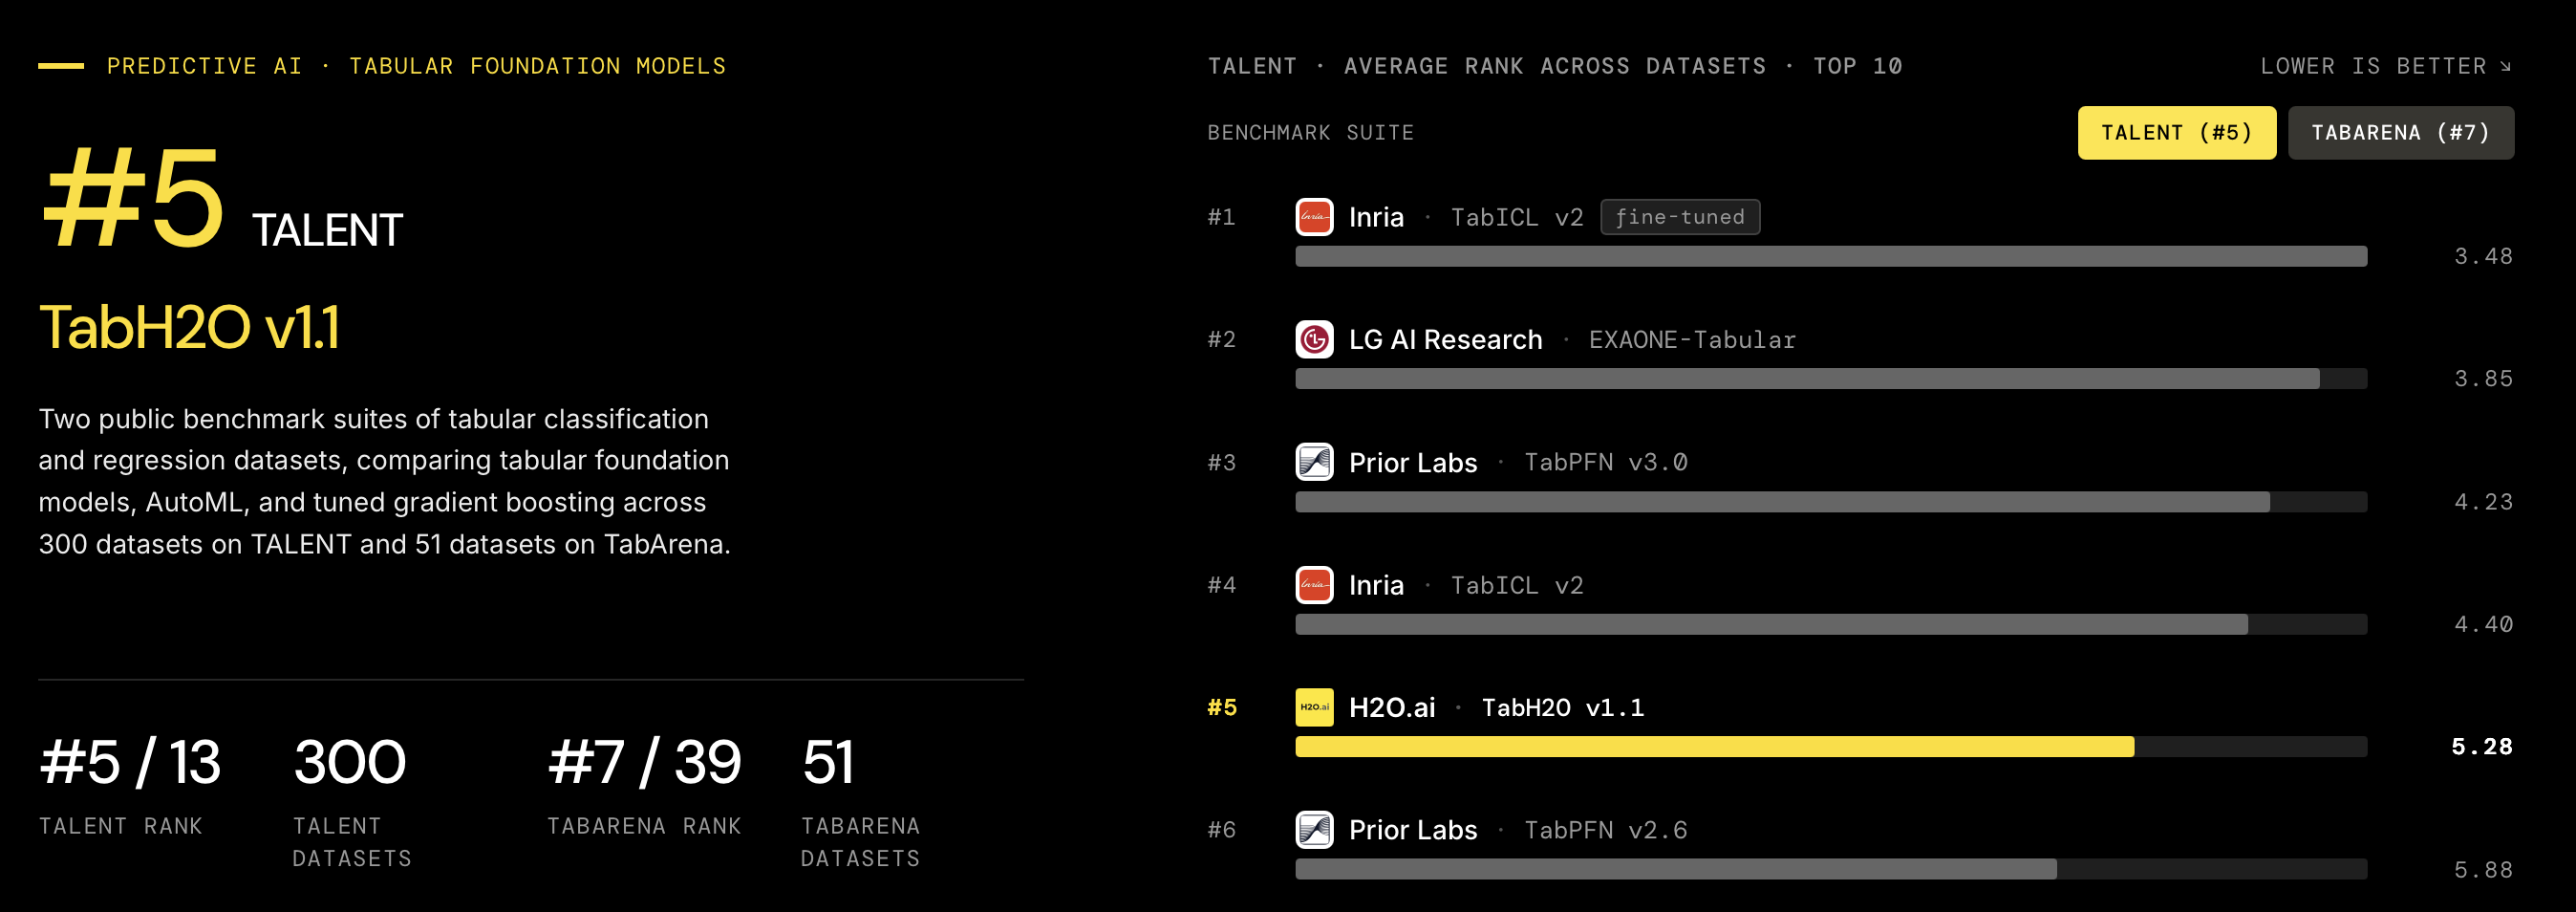

---

You can red the official technical report here: [TabH2O: A Unified Foundation Model for Tabular Prediction](https://arxiv.org/abs/2605.18383).

Track the best Predictive AI models in the world using our [Benchmarks](https://h2oai.github.io/benchmarks/).

---


## 1. Setup

The notebook calls `https://tabh2o.h2oai.com`, so **Internet** must be on: notebook settings, then Internet, then On.

Add the API key as a Kaggle secret:

1. Open [tabh2o.h2oai.com/dashboard](https://tabh2o.h2oai.com/dashboard) and copy the key.
2. In the notebook editor, open **Add-ons → Secrets** (next to Settings).
3. Add a secret named `TABH2O_API_KEY` and paste the key as the value.
4. Attach the secret to this notebook and run the next cell.

Locally, the same cell reads the `TABH2O_API_KEY` environment variable instead.

**Alternative:** set the `TABH2O_API_KEY` environment variable locally running the follozing command on your terminal

```
export TABH2O_API_KEY="tabh2o_live_"
```
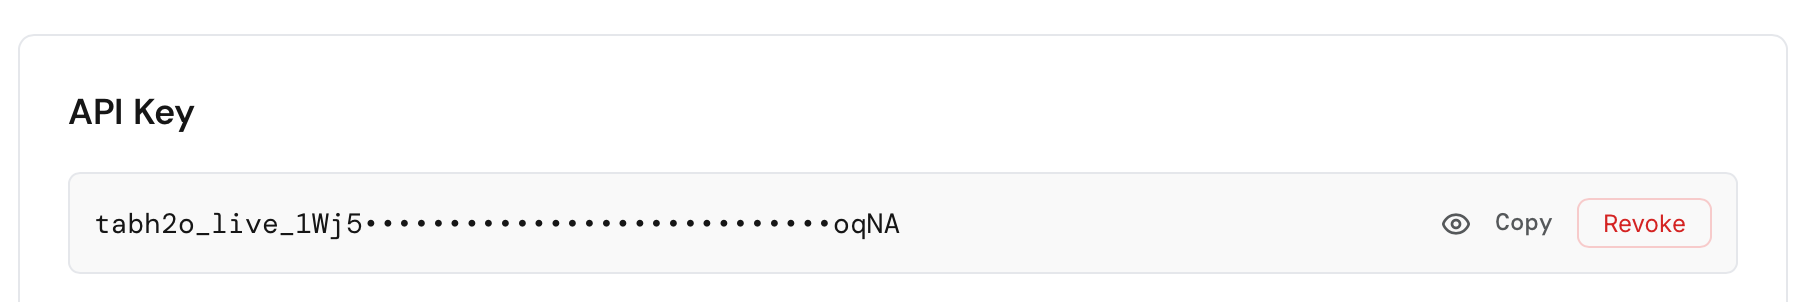
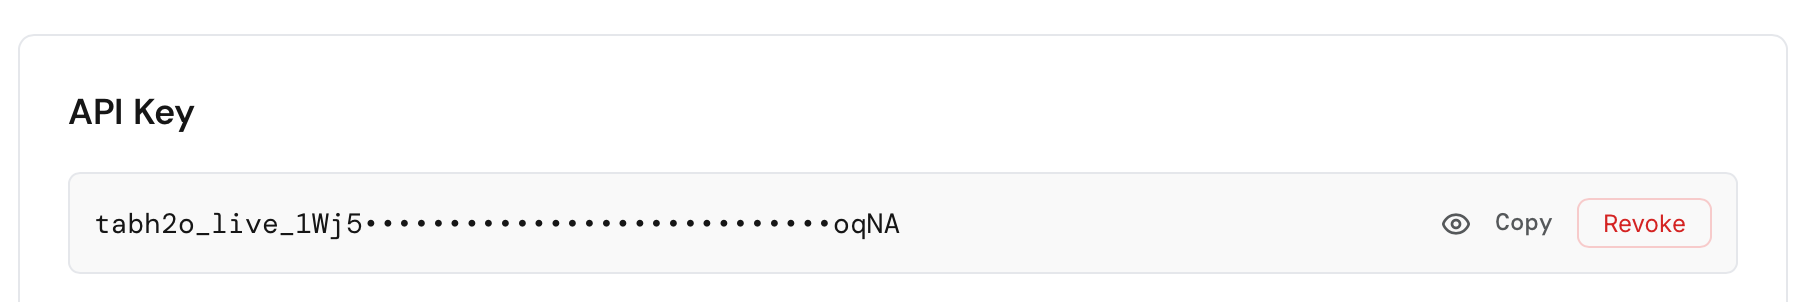

You can also **run the models locally**, install the package as follows:

```
from h2ofm import TabH2O

model = TabH2O.from_pretrained("h2oai/tabh2o-v1.1")
result = model.classify(X_train, y_train, X_test)

result.probabilities  # (n_test, n_classes), columns follow result.classes
result.labels  # (n_test,), the most probable class
```

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import requests
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

API_URL = "https://tabh2o.h2oai.com/api/v1/predict"
DATA_DIR = "/kaggle/input/competitions/playground-series-s6e11"
TARGET = "is_fraud"
CONTEXT = 150_000
MAX_ROWS = 200_000
SEED = 0

def load_api_key():
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        secret_value_0 = user_secrets.get_secret("TABH2O_API_KEY")
        return secret_value_0
    except Exception:
        return os.environ.get("TABH2O_API_KEY", "")

API_KEY = load_api_key()
assert API_KEY, "Add a Kaggle secret named TABH2O_API_KEY, or set that environment variable."
print("API key loaded.")


API key loaded.


## 2. Load the data

Drop `id`. It is only a row key, and the submission joins it back on at the end.


In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv", index_col="id")
test = pd.read_csv(f"{DATA_DIR}/test.csv", index_col="id")

print(f"Training set: {len(train):,} rows x {train.shape[1]} columns")
print(f"Test set: {len(test):,} rows")
print(f"Fraud rate: {train[TARGET].mean():.4f}")
train.head()


Training set: 699,960 rows x 25 columns
Test set: 299,984 rows
Fraud rate: 0.0167


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
id,,,,,,,,,,,,,,,,,,,,,
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## 3. TabH2O Model 

### Why TabH2O?

- **Minimal preprocessing.** TabH2O handles categorical features and missing values internally. We can use our data with minimal preparation.
- **No model training.** TabH2O is already pretrained. It uses our labeled data as context to make predictions, a process known as *in-context learning*.
- **Minimal hyperparameter tuning.** Unlike traditional models such as XGBoost or LightGBM, we can obtain predictions without running multiple training and optimization experiments.
- **Strong out-of-the-box performance.** TabH2O is designed to deliver competitive accuracy without extensive feature engineering or model optimization.
- **Direct probability predictions.** Since the competition uses ROC AUC, we can directly submit the predicted probability of fraud.

### Preparing context

TabH2O reads numerics and categoricals as they are, including missing values. Nothing here is imputed or encoded.

One request cannot hold the full training file. Each request below uses 150,000 training rows: all of the fraud rows, plus a sample of the legitimate ones. That leaves 50,000 test rows in the same request.



In [3]:
def make_context(frame, n=CONTEXT, seed=SEED):
    fraud = frame[frame[TARGET] == 1]
    legit = frame[frame[TARGET] == 0]
    if len(fraud) >= n:
        raise RuntimeError(f"{len(fraud)} fraud rows do not fit in a context of {n}.")
    picked = legit.sample(n=n - len(fraud), random_state=seed)
    return pd.concat([fraud, picked]).sample(frac=1, random_state=seed)

print(f"Fraud rows: {int((train[TARGET] == 1).sum()):,}")
print(f"Context: {CONTEXT:,} rows, including every fraud row")


Fraud rows: 11,689
Context: 150,000 rows, including every fraud row


## 4. Call the API

`to_json(orient="values")` turns `NaN` into JSON `null`. The response carries a predicted label and a probability for each class. The submission uses the probability of class `1`.


In [4]:
def to_rows(frame):
    return json.loads(frame.to_json(orient="values"))

def tabh2o_predict(train_df, test_df, timeout=1800):
    payload = {
        "train": {"data": to_rows(train_df), "columns": train_df.columns.tolist()},
        "test": {"data": to_rows(test_df), "columns": test_df.columns.tolist()},
        "target_column": TARGET,
        "task": "classification",
    }
    headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}
    response = requests.post(API_URL, headers=headers, json=payload, timeout=timeout)
    if response.status_code == 429:
        wait = int(response.headers.get("Retry-After", 60))
        print(f"Rate limited, waiting {wait}s...")
        time.sleep(wait)
        response = requests.post(API_URL, headers=headers, json=payload, timeout=timeout)
    response.raise_for_status()
    return response.json()

def fraud_probability(result):
    labels = np.array([str(v)[:-2] if str(v).endswith(".0") else str(v) for v in result["predictions"]])
    proba = np.asarray(result["probabilities"], dtype=float)
    classes = np.array(sorted(set(labels.tolist())))
    if proba.shape != (len(labels), len(classes)):
        raise RuntimeError(f"Unexpected probabilities shape {proba.shape}")
    if np.mean(classes[proba.argmax(1)] == labels) < 0.99:
        raise RuntimeError("Probability columns are not in sorted class order")
    return proba[:, int(np.where(classes == "1")[0][0])]


## 5. Check a holdout

A small context and 8,000 held-out training rows. This is a ranking check before the test file is scored.


In [5]:
fit, hold = train_test_split(train, test_size=8000, random_state=SEED, stratify=train[TARGET])
hold_y = hold[TARGET].to_numpy()
holdout = tabh2o_predict(make_context(fit, n=20_000, seed=1), hold.drop(columns=[TARGET]))
hold_score = fraud_probability(holdout)
print(f"Holdout ROC AUC: {roc_auc_score(hold_y, hold_score):.4f}  ({len(hold):,} rows)")
print(f"Model: {holdout['metadata']['model']}")
print(f"API latency: {holdout['metadata']['time_ms']} ms")


Holdout ROC AUC: 0.9329  (8,000 rows)
Model: tabh2o_v1.1_20260601
API latency: 3084 ms


## 6. Predict the test set

The same 150,000-row context is sent with every batch. Six requests cover the test file.


In [6]:
context = make_context(train)
test_X = test.copy()
room = MAX_ROWS - len(context)
parts = []
for start in range(0, len(test_X), room):
    batch = test_X.iloc[start : start + room]
    started = time.perf_counter()
    result = tabh2o_predict(context, batch)
    parts.append(fraud_probability(result))
    print(f"rows {start}:{start + len(batch)} in {time.perf_counter() - started:.0f}s")

predictions = np.concatenate(parts)
print(f"{len(predictions):,} probabilities, mean {predictions.mean():.4f}")


rows 0:50000 in 59s
rows 50000:100000 in 59s
rows 100000:150000 in 57s
rows 150000:200000 in 58s
rows 200000:250000 in 61s
rows 250000:299984 in 58s
299,984 probabilities, mean 0.0414


## 7. Write the submission

`is_fraud` is the predicted probability, not a hard label. ROC AUC uses the ranking.


In [7]:
submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
if not np.array_equal(submission["id"].to_numpy(), test.index.to_numpy()):
    raise RuntimeError("Test ids do not match sample_submission.csv")
submission[TARGET] = predictions
submission.to_csv("submission.csv", index=False)
print(f"Wrote submission.csv ({len(submission):,} rows)")
submission.head()


Wrote submission.csv (299,984 rows)


,id,is_fraud
0,699960,0.000285
1,699961,0.000115
2,699962,0.308932
3,699963,0.002845
4,699964,0.004021


## 8. Submit

Upload `submission.csv` on the competition page, or submit this notebook after it has run with Internet on.

[Playground Series S6E11 submissions](https://www.kaggle.com/competitions/playground-series-s6e11/submissions)

Docs: <https://tabh2o.h2oai.com/docs>
